
# E-commerce Order Profit Analysis

## Business Problem
The objective of this project is to analyze e-commerce order data to understand sales performance, profitability, customer behaviour, and product performance.

## Business Questions

1. What is the total sales and profit?
2. Which product categories generate the highest profit?
3. Which cities generate the highest sales?
4. How do discounts affect business profitability?


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/ecommerce_data.csv")

df.head()

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/ecommerce_data.csv")

df.head()

Matplotlib is building the font cache; this may take a moment.


,Order_ID,Order_Date,City,Product_Category,Payment_Method,Customer_Type,Items_Count,Unit_Price_INR,Discount_Percent,Delivery_Days,Browsing_Time_Min,Profit_INR
0,O1102,2026-03-11,Mumbai,Home & Kitchen,NaN,New,4,1973.0,12,5,23.4,847
1,O1219,2025-04-09,Hyderabad,Fashion,Cash on Delivery,New,4,1425.0,17,4,9.9,869
2,O1101,2026-01-07,Delhi,Home & Kitchen,Credit Card,New,3,1753.0,6,5,19.1,501
3,O1226,2025-01-22,Mumbai,Home & Kitchen,UPI,New,2,1638.0,15,5,9.9,386
4,O1155,2026-10-30,Bengaluru,Home & Kitchen,Credit Card,New,3,1295.0,17,5,23.0,227


In [2]:
df.shape

(255, 12)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           255 non-null    str    
 1   Order_Date         255 non-null    str    
 2   City               255 non-null    str    
 3   Product_Category   255 non-null    str    
 4   Payment_Method     250 non-null    str    
 5   Customer_Type      249 non-null    str    
 6   Items_Count        255 non-null    int64  
 7   Unit_Price_INR     250 non-null    float64
 8   Discount_Percent   255 non-null    int64  
 9   Delivery_Days      255 non-null    int64  
 10  Browsing_Time_Min  251 non-null    float64
 11  Profit_INR         255 non-null    int64  
dtypes: float64(2), int64(4), str(6)
memory usage: 24.0 KB


In [4]:
df.describe()

,Items_Count,Unit_Price_INR,Discount_Percent,Delivery_Days,Browsing_Time_Min,Profit_INR
count,255.000000,250.000000,255.000000,255.000000,251.000000,255.000000
mean,3.564706,3097.372000,14.701961,4.352941,20.715936,668.643137
std,1.434505,3083.356914,11.657067,1.562649,10.111664,339.783155
min,1.000000,204.000000,-20.000000,1.000000,1.100000,40.000000
25%,3.000000,1043.500000,8.500000,3.000000,12.750000,416.500000
50%,3.000000,1643.000000,14.000000,4.000000,19.300000,690.000000
75%,4.500000,4514.750000,20.000000,5.000000,27.300000,905.500000
max,9.000000,17895.000000,135.000000,9.000000,52.400000,1686.000000


In [5]:
df.isnull().sum()

Order_ID             0
Order_Date           0
City                 0
Product_Category     0
Payment_Method       5
Customer_Type        6
Items_Count          0
Unit_Price_INR       5
Discount_Percent     0
Delivery_Days        0
Browsing_Time_Min    4
Profit_INR           0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(5)

In [7]:
df[df.duplicated(keep=False)]

,Order_ID,Order_Date,City,Product_Category,Payment_Method,Customer_Type,Items_Count,Unit_Price_INR,Discount_Percent,Delivery_Days,Browsing_Time_Min,Profit_INR
75,O1183,2025-03-14,Hyderabad,Beauty,UPI,Returning,6,307.0,5,5,10.6,1398
78,O1193,2025-09-20,Delhi,Home & Kitchen,UPI,Premium,2,2571.0,27,5,14.2,40
79,O1193,2025-09-20,Delhi,Home & Kitchen,UPI,Premium,2,2571.0,27,5,14.2,40
112,O1241,2025-09-17,Mumbai,Fashion,UPI,Premium,3,1819.0,13,5,27.9,596
117,O1111,2024-12-02,Delhi,Electronics,UPI,Returning,5,8722.0,20,4,32.3,802
129,O1241,2025-09-17,Mumbai,Fashion,UPI,Premium,3,1819.0,13,5,27.9,596
142,O1183,2025-03-14,Hyderabad,Beauty,UPI,Returning,6,307.0,5,5,10.6,1398
156,O1211,2025-07-22,Mumbai,Electronics,Cash on Delivery,New,3,8453.0,-20,3,35.6,522
178,O1211,2025-07-22,Mumbai,Electronics,Cash on Delivery,New,3,8453.0,-20,3,35.6,522
191,O1111,2024-12-02,Delhi,Electronics,UPI,Returning,5,8722.0,20,4,32.3,802


In [8]:
df_clean = df.drop_duplicates().copy()

In [9]:
df_clean.shape

(250, 12)

In [10]:
df_clean[df_clean.isnull().any(axis=1)]

,Order_ID,Order_Date,City,Product_Category,Payment_Method,Customer_Type,Items_Count,Unit_Price_INR,Discount_Percent,Delivery_Days,Browsing_Time_Min,Profit_INR
0,O1102,2026-03-11,Mumbai,Home & Kitchen,NaN,New,4,1973.0,12,5,23.4,847
13,O1023,2025-02-20,Mumbai,Electronics,Credit Card,Returning,3,8596.0,10,5,NaN,372
16,O1040,2026-05-25,Mumbai,Electronics,NaN,New,2,8399.0,13,4,19.3,582
26,O1232,2024-12-21,Mumbai,Electronics,Credit Card,Returning,2,6780.0,24,5,NaN,81
28,O1243,2026-01-19,Hyderabad,Fashion,Credit Card,Returning,5,NaN,10,4,22.1,751
38,O1236,2025-03-22,Bengaluru,Home & Kitchen,Cash on Delivery,Returning,2,1310.0,16,7,NaN,403
69,O1207,2026-07-08,Delhi,Electronics,Credit Card,New,3,3419.0,25,4,NaN,308
72,O1187,2026-03-29,Delhi,Fashion,UPI,New,5,NaN,15,4,20.0,822
96,O1083,2025-07-06,Delhi,Electronics,Net Banking,NaN,6,7294.0,1,2,38.1,1686
113,O1093,2026-07-25,Bengaluru,Books,Credit Card,NaN,3,383.0,23,6,12.5,481


In [11]:
df_clean.isnull().sum()

Order_ID             0
Order_Date           0
City                 0
Product_Category     0
Payment_Method       5
Customer_Type        6
Items_Count          0
Unit_Price_INR       5
Discount_Percent     0
Delivery_Days        0
Browsing_Time_Min    4
Profit_INR           0
dtype: int64

In [12]:
df_clean["Payment_Method"] = df_clean["Payment_Method"].fillna("Unknown")

df_clean["Customer_Type"] = df_clean["Customer_Type"].fillna("Unknown")

In [13]:
df_clean[["Payment_Method", "Customer_Type"]].isnull().sum()

Payment_Method    0
Customer_Type     0
dtype: int64

In [14]:
df_clean[["Unit_Price_INR", "Browsing_Time_Min"]].median()

Unit_Price_INR       1637.0
Browsing_Time_Min      19.3
dtype: float64

In [15]:
df_clean["Unit_Price_INR"] = df_clean["Unit_Price_INR"].fillna(
    df_clean["Unit_Price_INR"].median()
)

df_clean["Browsing_Time_Min"] = df_clean["Browsing_Time_Min"].fillna(
    df_clean["Browsing_Time_Min"].median()
)

In [16]:
df_clean.isnull().sum()

Order_ID             0
Order_Date           0
City                 0
Product_Category     0
Payment_Method       0
Customer_Type        0
Items_Count          0
Unit_Price_INR       0
Discount_Percent     0
Delivery_Days        0
Browsing_Time_Min    0
Profit_INR           0
dtype: int64

In [17]:
df_clean[
    (df_clean["Discount_Percent"] < 0) |
    (df_clean["Discount_Percent"] > 100)
]

,Order_ID,Order_Date,City,Product_Category,Payment_Method,Customer_Type,Items_Count,Unit_Price_INR,Discount_Percent,Delivery_Days,Browsing_Time_Min,Profit_INR
73,O1084,2025-11-29,Bengaluru,Fashion,Cash on Delivery,Returning,4,2054.0,135,6,9.6,539
156,O1211,2025-07-22,Mumbai,Electronics,Cash on Delivery,New,3,8453.0,-20,3,35.6,522


In [18]:
df_clean.loc[
    (df_clean["Discount_Percent"] < 0) |
    (df_clean["Discount_Percent"] > 100),
    ["Order_ID", "City", "Product_Category", "Unit_Price_INR", "Discount_Percent", "Profit_INR"]
]

,Order_ID,City,Product_Category,Unit_Price_INR,Discount_Percent,Profit_INR
73,O1084,Bengaluru,Fashion,2054.0,135,539
156,O1211,Mumbai,Electronics,8453.0,-20,522


In [19]:
df_analysis = df_clean[
    (df_clean["Discount_Percent"] >= 0) &
    (df_clean["Discount_Percent"] <= 100)
].copy()

In [20]:
df_analysis.shape

(248, 12)

In [21]:
df_analysis["City"] = df_analysis["City"].str.strip().str.title()

In [22]:
df_analysis["City"].value_counts()

City
Mumbai       69
Delhi        69
Bengaluru    51
Hyderabad    36
Ghaziabad    23
Name: count, dtype: int64

In [23]:
df_analysis["Order_Date"] = pd.to_datetime(
    df_analysis["Order_Date"],
    errors="coerce"
)

In [24]:
df_analysis["Order_Date"].dtype

dtype('<M8[us]')

In [25]:
df_analysis.info()

<class 'pandas.DataFrame'>
Index: 248 entries, 0 to 254
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Order_ID           248 non-null    str           
 1   Order_Date         248 non-null    datetime64[us]
 2   City               248 non-null    str           
 3   Product_Category   248 non-null    str           
 4   Payment_Method     248 non-null    str           
 5   Customer_Type      248 non-null    str           
 6   Items_Count        248 non-null    int64         
 7   Unit_Price_INR     248 non-null    float64       
 8   Discount_Percent   248 non-null    int64         
 9   Delivery_Days      248 non-null    int64         
 10  Browsing_Time_Min  248 non-null    float64       
 11  Profit_INR         248 non-null    int64         
dtypes: datetime64[us](1), float64(2), int64(4), str(5)
memory usage: 25.2 KB


In [26]:
df_analysis.to_csv(
    "../data/processed/ecommerce_cleaned.csv",
    index=False
)

In [27]:
total_revenue = (
    df_analysis["Unit_Price_INR"]
    * df_analysis["Items_Count"]
    * (1 - df_analysis["Discount_Percent"] / 100)
).sum()

total_profit = df_analysis["Profit_INR"].sum()

total_orders = df_analysis["Order_ID"].nunique()

average_order_value = total_revenue / total_orders

print("Total Revenue:", round(total_revenue, 2))
print("Total Profit:", total_profit)
print("Total Orders:", total_orders)
print("Average Order Value:", round(average_order_value, 2))

Total Revenue: 2344995.85
Total Profit: 166085
Total Orders: 248
Average Order Value: 9455.63


In [28]:
category_profit = (
    df_analysis.groupby("Product_Category")["Profit_INR"]
    .sum()
    .sort_values(ascending=False)
)

print(category_profit)

Product_Category
Fashion           48550
Electronics       43084
Home & Kitchen    34142
Beauty            27751
Books             12558
Name: Profit_INR, dtype: int64


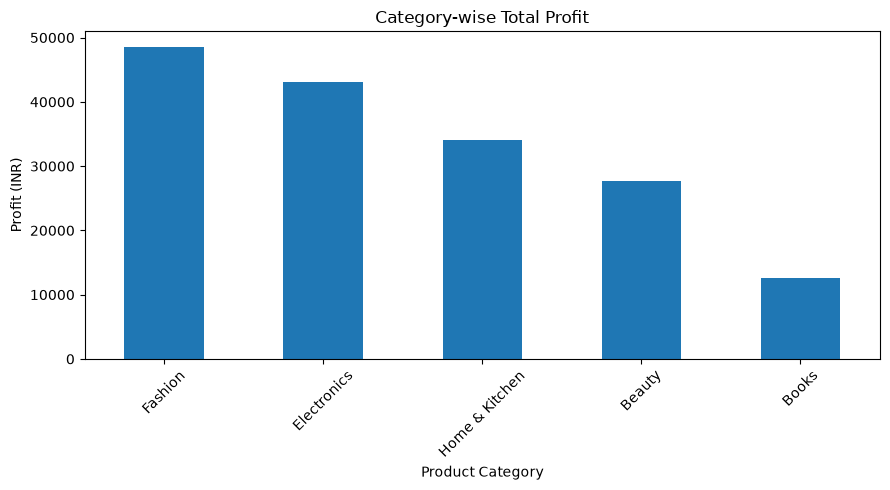

In [29]:
plt.figure(figsize=(9, 5))

category_profit.plot(kind="bar")

plt.title("Category-wise Total Profit")
plt.xlabel("Product Category")
plt.ylabel("Profit (INR)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [30]:
city_revenue = (
    df_analysis.assign(
        Revenue=df_analysis["Unit_Price_INR"]
        * df_analysis["Items_Count"]
        * (1 - df_analysis["Discount_Percent"] / 100)
    )
    .groupby("City")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(city_revenue)

City
Delhi        683165.76
Mumbai       635034.36
Bengaluru    389367.84
Hyderabad    377559.04
Ghaziabad    259868.85
Name: Revenue, dtype: float64


In [32]:
correlation = df_analysis["Discount_Percent"].corr(
    df_analysis["Profit_INR"]
)

print("Discount vs Profit Correlation:", round(correlation, 2))

Discount vs Profit Correlation: -0.58


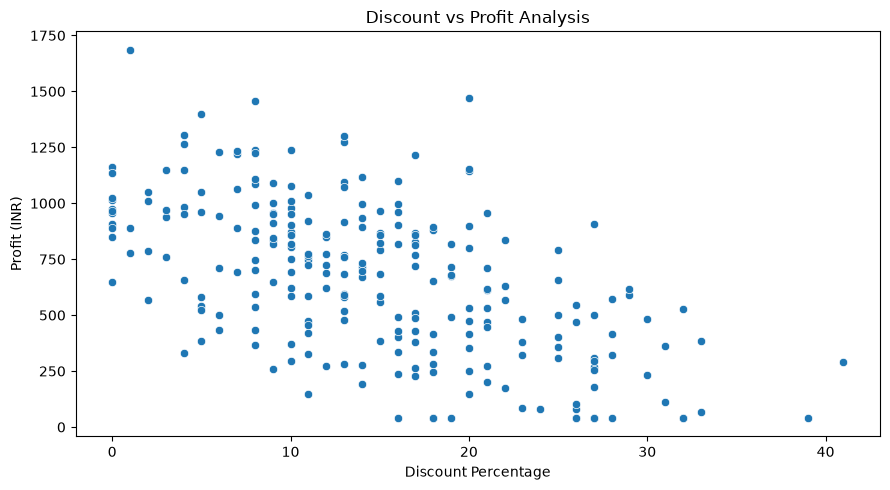

In [33]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df_analysis,
    x="Discount_Percent",
    y="Profit_INR"
)

plt.title("Discount vs Profit Analysis")
plt.xlabel("Discount Percentage")
plt.ylabel("Profit (INR)")

plt.tight_layout()
plt.show()

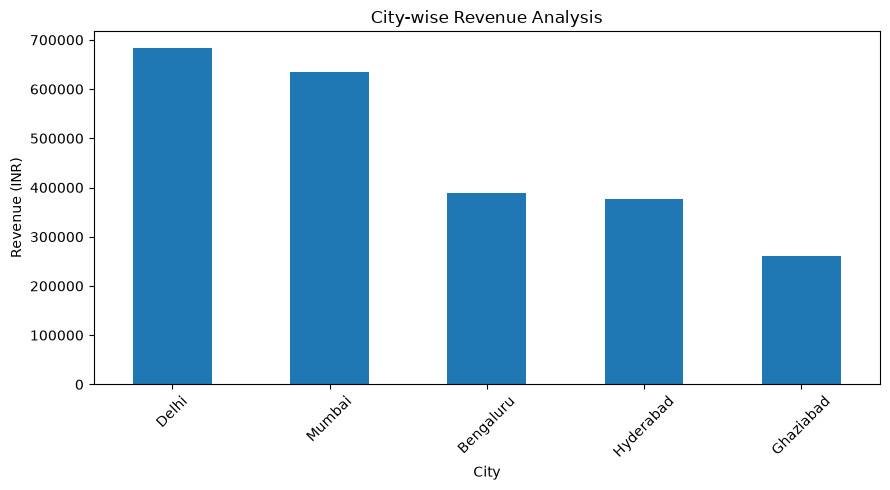

In [34]:
plt.figure(figsize=(9, 5))

city_revenue.plot(kind="bar")

plt.title("City-wise Revenue Analysis")
plt.xlabel("City")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [35]:
df_analysis["Revenue"] = (
    df_analysis["Unit_Price_INR"]
    * df_analysis["Items_Count"]
    * (1 - df_analysis["Discount_Percent"] / 100)
)

monthly_revenue = (
    df_analysis.groupby(df_analysis["Order_Date"].dt.month)["Revenue"]
    .sum()
)

print(monthly_revenue)

Order_Date
1     191787.46
2     129823.56
3     221680.56
4     307335.40
5     100020.03
6     215108.70
7     134502.41
8      98344.70
9     252129.80
10    221763.11
11    258132.77
12    214367.35
Name: Revenue, dtype: float64


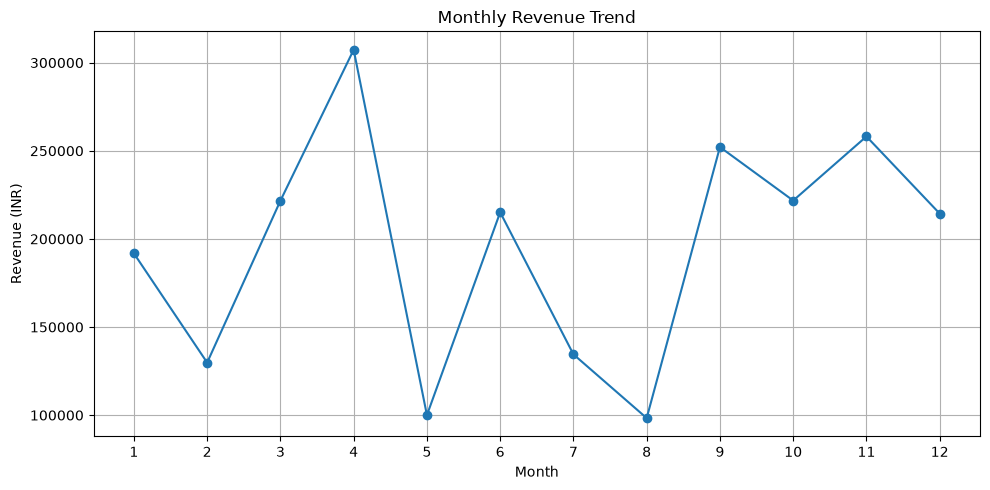

In [36]:
plt.figure(figsize=(10, 5))

monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.xticks(range(1, 13))

plt.grid(True)
plt.tight_layout()
plt.show()

## Business Insights

1. **Overall Performance:** The dataset contains 248 unique orders, generating total revenue of ₹23,44,995.85 and total profit of ₹1,66,085.

2. **Top Product Category:** Fashion generated the highest profit of ₹48,550.

3. **Lowest Product Category:** Books generated the lowest profit of ₹12,558.

4. **Top Performing City:** Delhi generated the highest revenue of ₹6,83,165.76.

5. **Lowest Performing City:** Ghaziabad generated the lowest revenue of ₹2,59,868.85.

6. **Discount Impact:** Discount and profit have a moderate negative correlation of -0.58.

7. **Monthly Performance:** April recorded the highest revenue, while August recorded the lowest revenue.

## Conclusion

The E-commerce Order Profit Analysis project helped identify sales trends, profitable product categories, city-wise revenue distribution, and the relationship between discounts and profit.

The analysis shows that Fashion is the most profitable category, Delhi generates the highest revenue, and April is the strongest month in terms of revenue.

The negative correlation between discount percentage and profit suggests that discount strategies should be monitored carefully.

## Business Recommendations

1. Focus on improving sales and profitability in the Fashion category.
2. Investigate the reasons behind lower revenue in Ghaziabad.
3. Review discount strategies to protect profit margins.
4. Study April's sales performance to identify successful business factors.
5. Explore ways to improve revenue during weaker months, especially August.

## Tools & Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook